# Project Title:
# Fake Job Posting Detection


It will identify a job as fake or legitimate mainly based on the patterns in its text and other job-related features.

Specifically, it looks at:

Job Description

Wording and content of the job advertisement.

Example: unusually unrealistic offers or suspicious instructions.

Company Profile

Information provided about the company.

Missing or unusual company information can become a learned feature.

Job Requirements

Skills, experience, education, and other requirements.

Benefits

Information about salary, incentives, work conditions, etc.

Job Title

The wording of the position.

These are the textual attributes your project document specifically says to emphasize.

Goal: Build a Machine Learning system that predicts whether a job posting is:

Fraudulent / Fake

Legitimate / Real

Step 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import string

from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import CountVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

Step 2: Load Dataset

In [2]:
df = pd.read_csv(
    '/content/fake_job_postings.csv',
    engine='python',
    on_bad_lines='skip'
)

df.head()

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


Check the first five rows:

In [3]:
df.head()

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


Step 3: Check Dataset Size

In [4]:
df.shape

(782, 18)

Step 4: Check Column Names

In [5]:
df.columns

Index(['job_id', 'title', 'location', 'department', 'salary_range',
       'company_profile', 'description', 'requirements', 'benefits',
       'telecommuting', 'has_company_logo', 'has_questions', 'employment_type',
       'required_experience', 'required_education', 'industry', 'function',
       'fraudulent'],
      dtype='object')

Step 5: Check Data Types

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 782 entries, 0 to 781
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   job_id               782 non-null    int64 
 1   title                782 non-null    object
 2   location             768 non-null    object
 3   department           240 non-null    object
 4   salary_range         126 non-null    object
 5   company_profile      677 non-null    object
 6   description          782 non-null    object
 7   requirements         672 non-null    object
 8   benefits             457 non-null    object
 9   telecommuting        782 non-null    int64 
 10  has_company_logo     782 non-null    int64 
 11  has_questions        782 non-null    int64 
 12  employment_type      666 non-null    object
 13  required_experience  492 non-null    object
 14  required_education   519 non-null    object
 15  industry             618 non-null    object
 16  function

Step 6: Check Missing Values

In [7]:
df.isnull().sum()

,0
job_id,0
title,0
location,14
department,542
salary_range,656
company_profile,105
description,0
requirements,110
benefits,325
telecommuting,0


To see missing values as percentages:

In [8]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage.sort_values(ascending=False)

,0
salary_range,83.887468
department,69.309463
benefits,41.560102
required_experience,37.084399
function,35.038363
required_education,33.631714
industry,20.971867
employment_type,14.833760
requirements,14.066496
company_profile,13.427110


Step 7: Check Duplicate Rows

In [9]:
df.duplicated().sum()

np.int64(0)

If duplicates exist:

In [10]:
df = df.drop_duplicates()

In [11]:
df.duplicated().sum()

np.int64(0)

Step 8: Explore the Target Variable

First identify your target column.

For a typical fake-job dataset, it may be:

fraudulent

In [12]:
df['fraudulent'].value_counts()

,count
fraudulent,
0,767
1,15


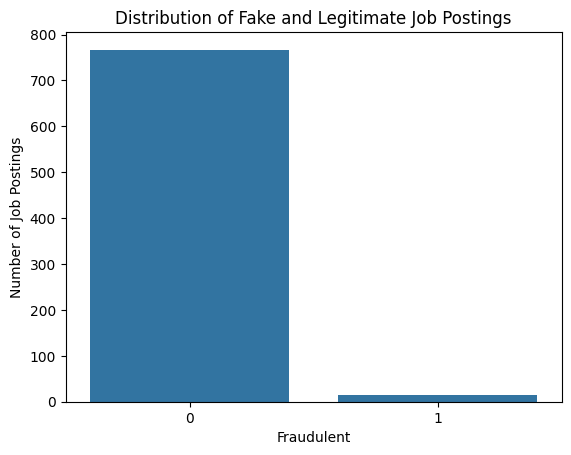

In [13]:
sns.countplot(x='fraudulent', data=df)

plt.title('Distribution of Fake and Legitimate Job Postings')
plt.xlabel('Fraudulent')
plt.ylabel('Number of Job Postings')
plt.show()

0 → Legitimate job
1 → Fraudulent job

Step 9: Handle Missing Values

For text columns, fill missing values with an empty string.

In [14]:
text_columns = [
    'title',
    'company_profile',
    'description',
    'requirements',
    'benefits'
]

In [15]:
for col in text_columns:
    df[col] = df[col].fillna('')

In [16]:
df[text_columns].isnull().sum()

,0
title,0
company_profile,0
description,0
requirements,0
benefits,0


Step 10: Analyze Text Features

Check the length of job descriptions:

In [17]:
df['description_length'] = df['description'].apply(len)

In [18]:
df['description_length'].describe()

,description_length
count,782.000000
mean,1213.746803
std,958.488541
min,15.000000
25%,513.250000
50%,998.000000
75%,1575.250000
max,7967.000000


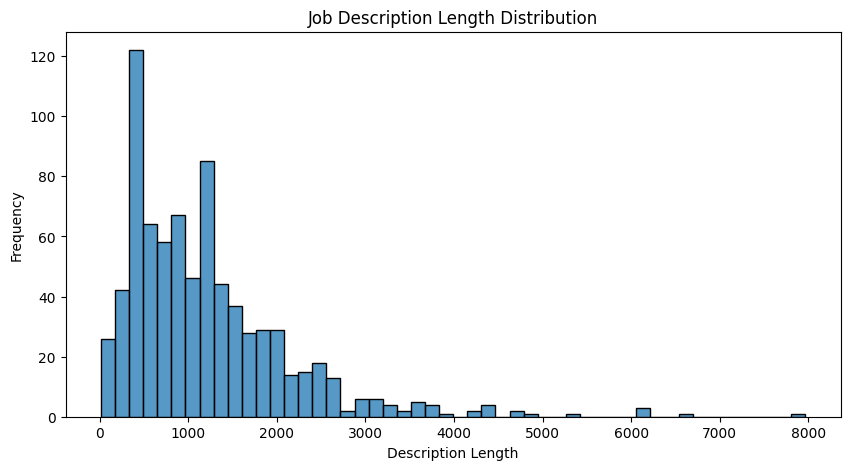

In [19]:
plt.figure(figsize=(10,5))

sns.histplot(df['description_length'], bins=50)

plt.title('Job Description Length Distribution')
plt.xlabel('Description Length')
plt.ylabel('Frequency')

plt.show()

Step 11: Analyze Numerical/Categorical Features

For numerical columns:

In [20]:
df.describe()

,job_id,telecommuting,has_company_logo,has_questions,fraudulent,description_length
count,782.000000,782.000000,782.000000,782.000000,782.000000,782.000000
mean,391.500000,0.026854,0.843990,0.433504,0.019182,1213.746803
std,225.888247,0.161761,0.363097,0.495876,0.137251,958.488541
min,1.000000,0.000000,0.000000,0.000000,0.000000,15.000000
25%,196.250000,0.000000,1.000000,0.000000,0.000000,513.250000
50%,391.500000,0.000000,1.000000,0.000000,0.000000,998.000000
75%,586.750000,0.000000,1.000000,1.000000,0.000000,1575.250000
max,782.000000,1.000000,1.000000,1.000000,1.000000,7967.000000


For categorical columns:

In [21]:
df.select_dtypes(include='object').nunique()

,0
title,600
location,426
department,117
salary_range,90
company_profile,287
description,671
requirements,529
benefits,321
employment_type,5
required_experience,7


You can also check individual categorical variables:

In [22]:
df['employment_type'].value_counts()

,count
employment_type,
Full-time,501
Contract,110
Part-time,40
Temporary,8
Other,7


Step 12: Clean Text Data

The project requires cleaning textual data before converting it into numerical features.

In [23]:
def clean_text(text):
    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

Step 13: Create Combined Text

Since the project emphasizes textual attributes such as job descriptions, requirements, and company profiles, we can combine them.

In [24]:
df['combined_text'] = (
    df['title'].fillna('') + ' ' +
    df['company_profile'].fillna('') + ' ' +
    df['description'].fillna('') + ' ' +
    df['requirements'].fillna('') + ' ' +
    df['benefits'].fillna('')
)

Step 14: Clean Combined Text

In [25]:
df['clean_text'] = df['combined_text'].apply(clean_text)

In [26]:
df['clean_text'] = df['combined_text'].apply(clean_text)

Step 15: Select X and y

Assuming the target is fraudulent:

In [27]:
X = df['clean_text']
y = df['fraudulent']

In [28]:
X.head()

,clean_text
0,marketing intern were food52 and weve created ...
1,customer service cloud video production 90 sec...
2,commissioning machinery assistant cma valor se...
3,account executive washington dc our passion fo...
4,bill review manager spotsource solutions llc i...


In [29]:
y.head()

,fraudulent
0,0
1,0
2,0
3,0
4,0


Step 16: Train-Test Split

The project requires dividing the data into training and testing subsets for unbiased evaluation.

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

This means:

80% → Training
20% → Testing

stratify=y maintains a similar fake/legitimate ratio in both sets.

Step 17: Convert Text into Numbers — TF-IDF

Machine Learning models cannot directly understand raw text.

Therefore, we convert text into numerical vectors.

Your project specifically suggests TF-IDF or CountVectorizer.

Use TF-IDF:

In [31]:
tfidf = TfidfVectorizer(
    max_features=10000,
    stop_words='english',
    ngram_range=(1, 2)
)

Fit only on training data:

In [32]:
X_train_tfidf = tfidf.fit_transform(X_train)

Transform test data:

In [33]:
X_test_tfidf = tfidf.transform(X_test)

Check dimensions:

In [34]:
X_train_tfidf.shape

(625, 10000)

In [35]:
X_test_tfidf.shape

(157, 10000)

Step 18: Train Logistic Regression

The project specifically asks for Logistic Regression as one classification algorithm.

In [36]:
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000, random_state=42)

Step 19: Make Predictions

In [37]:
y_pred_lr = lr_model.predict(X_test_tfidf)

Get probabilities:

In [38]:
y_prob_lr = lr_model.predict_proba(X_test_tfidf)[:, 1]

Step 20: Evaluate Logistic Regression

Accuracy

on testing data

In [39]:
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Accuracy:", accuracy_lr)

Accuracy: 0.9808917197452229


Precision

In [40]:
precision_lr = precision_score(y_test, y_pred_lr)
print("Precision:", precision_lr)

Precision: 0.0


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Recall

In [41]:
recall_lr = recall_score(y_test, y_pred_lr)
print("Recall:", recall_lr)

Recall: 0.0


F1 Score

In [42]:
f1_lr = f1_score(y_test, y_pred_lr)
print("F1 Score:", f1_lr)

F1 Score: 0.0


ROC-AUC

In [43]:
roc_auc_lr = roc_auc_score(y_test, y_prob_lr)
print("ROC-AUC:", roc_auc_lr)

ROC-AUC: 0.9978354978354979


Step 21: Classification Report

In [44]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       154
           1       0.00      0.00      0.00         3

    accuracy                           0.98       157
   macro avg       0.49      0.50      0.50       157
weighted avg       0.96      0.98      0.97       157



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


This provides:

Precision

Recall

F1-score

Support

The project asks you to evaluate using multiple metrics rather than relying only on accuracy.

Step 22: Confusion Matrix

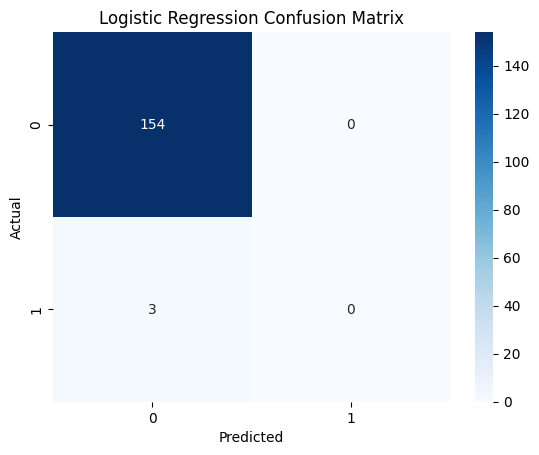

In [45]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Step 23: Train Naive Bayes

The project also specifically requires experimenting with Naive Bayes.

In [46]:
nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

MultinomialNB()

Step 24: Predict Using Naive Bayes

In [47]:
y_pred_nb = nb_model.predict(X_test_tfidf)

Get probabilities:

In [48]:
y_prob_nb = nb_model.predict_proba(X_test_tfidf)[:, 1]

Step 25: Evaluate Naive Bayes

In [49]:
accuracy_nb = accuracy_score(y_test, y_pred_nb)

precision_nb = precision_score(y_test, y_pred_nb)

recall_nb = recall_score(y_test, y_pred_nb)

f1_nb = f1_score(y_test, y_pred_nb)

roc_auc_nb = roc_auc_score(y_test, y_prob_nb)

print("Accuracy:", accuracy_nb)
print("Precision:", precision_nb)
print("Recall:", recall_nb)
print("F1 Score:", f1_nb)
print("ROC-AUC:", roc_auc_nb)

Accuracy: 0.9808917197452229
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
ROC-AUC: 0.7705627705627707


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Step 26: Classification Report for Naive Bayes

In [50]:
print(classification_report(y_test, y_pred_nb))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       154
           1       0.00      0.00      0.00         3

    accuracy                           0.98       157
   macro avg       0.49      0.50      0.50       157
weighted avg       0.96      0.98      0.97       157



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Step 27: Confusion Matrix for Naive Bayes

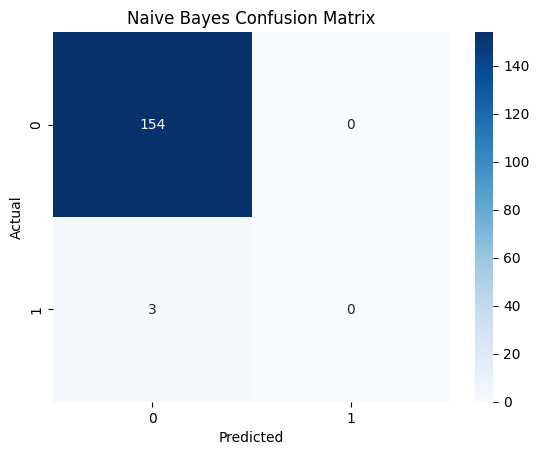

In [51]:
cm_nb = confusion_matrix(y_test, y_pred_nb)

sns.heatmap(
    cm_nb,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Naive Bayes Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

Step 28: Compare Both Models

In [52]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Naive Bayes'
    ],
    'Accuracy': [
        accuracy_lr,
        accuracy_nb
    ],
    'Precision': [
        precision_lr,
        precision_nb
    ],
    'Recall': [
        recall_lr,
        recall_nb
    ],
    'F1 Score': [
        f1_lr,
        f1_nb
    ],
    'ROC-AUC': [
        roc_auc_lr,
        roc_auc_nb
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.980892,0.0,0.0,0.0,0.997835
1,Naive Bayes,0.980892,0.0,0.0,0.0,0.770563


This directly supports the required comparative analysis across models.

Step 29: Compare Models Visually

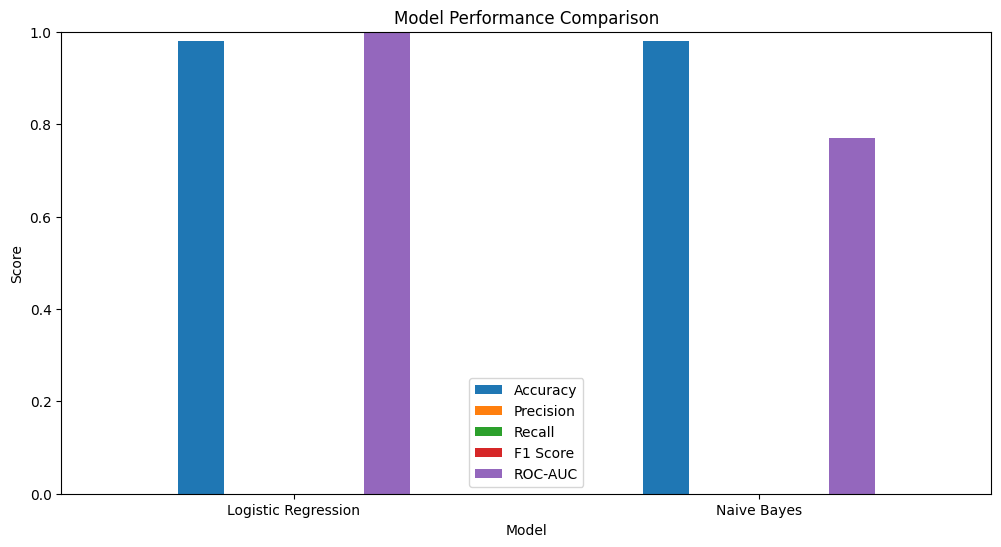

In [53]:
results.set_index('Model').plot(
    kind='bar',
    figsize=(12,6)
)

plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.show()

Step 30: ROC Curve

For Logistic Regression:

In [54]:
fpr_lr, tpr_lr, _ = roc_curve(
    y_test,
    y_prob_lr
)

For Naive Bayes:

In [55]:
fpr_nb, tpr_nb, _ = roc_curve(
    y_test,
    y_prob_nb
)

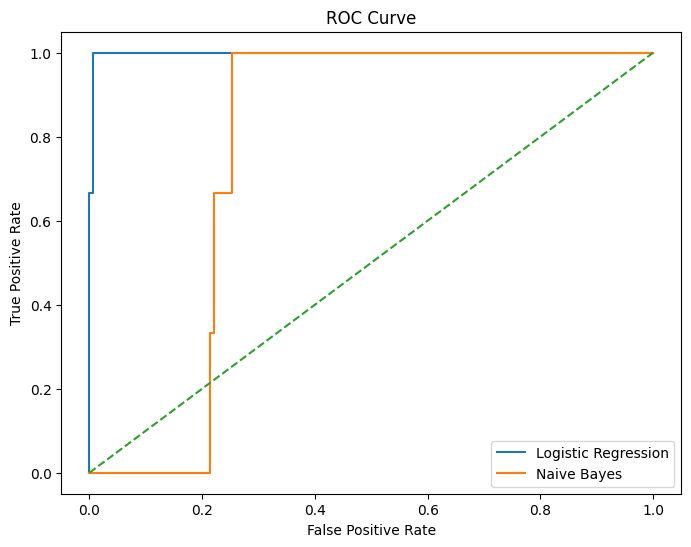

In [56]:
plt.figure(figsize=(8,6))

plt.plot(
    fpr_lr,
    tpr_lr,
    label='Logistic Regression'
)

plt.plot(
    fpr_nb,
    tpr_nb,
    label='Naive Bayes'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('ROC Curve')

plt.legend()

plt.show()

Step 31: Hyperparameter Tuning

The project encourages parameter tuning to observe performance changes.

For Logistic Regression:

In [57]:
param_grid = {
    'C': [0.1, 1, 10],
    'solver': ['liblinear', 'lbfgs']
}

Create GridSearchCV:

In [58]:
grid_lr = GridSearchCV(
    LogisticRegression(max_iter=1000),
    param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1
)

Train:

In [59]:
grid_lr.fit(X_train_tfidf, y_train)

GridSearchCV(cv=3, estimator=LogisticRegression(max_iter=1000), n_jobs=-1,
             param_grid={'C': [0.1, 1, 10], 'solver': ['liblinear', 'lbfgs']},
             scoring='f1')

Best parameters:

In [60]:
print("Best Parameters:")
print(grid_lr.best_params_)

Best Parameters:
{'C': 0.1, 'solver': 'liblinear'}


Best score:

In [61]:
print("Best F1 Score:")
print(grid_lr.best_score_)

Best F1 Score:
0.0


Step 32: Evaluate Tuned Model

In [62]:
best_lr = grid_lr.best_estimator_

y_pred_tuned = best_lr.predict(X_test_tfidf)

y_prob_tuned = best_lr.predict_proba(X_test_tfidf)[:, 1]

In [63]:
print("Accuracy:",
      accuracy_score(y_test, y_pred_tuned))

print("Precision:",
      precision_score(y_test, y_pred_tuned))

print("Recall:",
      recall_score(y_test, y_pred_tuned))

print("F1 Score:",
      f1_score(y_test, y_pred_tuned))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_tuned))

Accuracy: 0.9808917197452229
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
ROC-AUC: 0.9653679653679654


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Step 33: Test a New Job Posting

Now we create the actual prediction system.

In [64]:
new_job = """
We are looking for a software developer to join our company.
The candidate should have experience in Python, SQL and web development.
The selected candidate will work with our development team.
"""

Clean it:

In [65]:
new_job_clean = clean_text(new_job)

Convert to TF-IDF:

In [66]:
new_job_tfidf = tfidf.transform([new_job_clean])

Predict:

In [67]:
prediction = best_lr.predict(new_job_tfidf)

Step 34: Display Prediction

In [68]:
if prediction[0] == 1:
    print("⚠️ This job posting is likely FRAUDULENT.")
else:
    print("✅ This job posting is likely LEGITIMATE.")

✅ This job posting is likely LEGITIMATE.


This fulfills the final requirement of classifying an unseen job posting.

Step 35: Create a Simple Prediction Function

Instead of writing everything every time:

In [69]:
def predict_job(job_text):

    cleaned = clean_text(job_text)

    vector = tfidf.transform([cleaned])

    prediction = best_lr.predict(vector)[0]

    probability = best_lr.predict_proba(vector)[0][1]

    if prediction == 1:
        result = "Fraudulent"
    else:
        result = "Legitimate"

    print("Prediction:", result)
    print("Fraud Probability:", round(probability * 100, 2), "%")

In [70]:
predict_job("""
We are hiring a software developer with Python experience.
The employee will work on web applications and databases.
""")

Prediction: Legitimate
Fraud Probability: 6.54 %


Complete Project Flow

Dataset

   ↓

Data Loading

   ↓

Data Understanding

   ↓

Missing Value Handling

   ↓

Duplicate Removal

   ↓

Exploratory Data Analysis

   ↓

Text Cleaning

   ↓

Feature Selection

   ↓

Combine Text Features

   ↓

Train-Test Split

   ↓

TF-IDF

   ↓

Logistic Regression

   ↓

Naive Bayes

   ↓

Predictions

   ↓

Evaluation

   ↓

Confusion Matrix

   ↓

Precision / Recall / F1 / ROC-AUC

   ↓

Model Comparison

   ↓

Hyperparameter Tuning

   ↓

Best Model

   ↓

New Job Posting

   ↓
   
Fake / Legitimate Prediction


Important

Your uploaded project specification says the system should not rely only on accuracy, and the final model should be justified through comparative analysis and evaluation of its limitations.